# Exploring the Olist data

One section per table. Each section starts with the same general checks, then answers the table-specific questions:

1. **Shape**: how many rows and columns?
2. **Grain**: what does one row represent? (`.head()`)
3. **Key**: which column uniquely identifies a row, and is it really unique?
4. **Links**: which columns join to other tables?
5. **Types**: what type is each column, and are dates stored as text?
6. **Missing values**: which columns have them, and why?
7. **Realistic values**: `.describe()` and `.value_counts()`
8. **Surprises**: anything unexpected

The findings are written up in `docs/data_sources.md`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data/olist")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


def profile(df, name, key=None):
    """General checks that every table gets."""
    print(f"===== {name} =====")
    print("Shape (rows, columns):", df.shape)

    if key is not None:
        cols = [key] if isinstance(key, str) else list(key)
        unique = not df.duplicated(subset=cols).any()
        print(f"Key {cols} unique: {unique}")
    print("Fully duplicated rows:", df.duplicated().sum())

    print("\nData types:")
    print(df.dtypes)

    nulls = df.isna().sum()
    print("\nMissing values (only columns that have any):")
    print(nulls[nulls > 0] if nulls.any() else "none")

    print("\nDistinct values per column:")
    print(df.nunique())

In [2]:
orders = pd.read_csv(DATA / "olist_orders_dataset.csv")
order_items = pd.read_csv(DATA / "olist_order_items_dataset.csv")
payments = pd.read_csv(DATA / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(DATA / "olist_order_reviews_dataset.csv")
customers = pd.read_csv(DATA / "olist_customers_dataset.csv")
products = pd.read_csv(DATA / "olist_products_dataset.csv")
category_translation = pd.read_csv(DATA / "product_category_name_translation.csv")
sellers = pd.read_csv(DATA / "olist_sellers_dataset.csv")
geolocation = pd.read_csv(DATA / "olist_geolocation_dataset.csv")

tables = {
    "orders": orders,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
    "customers": customers,
    "products": products,
    "category_translation": category_translation,
    "sellers": sellers,
    "geolocation": geolocation,
}
pd.DataFrame({name: df.shape for name, df in tables.items()}, index=["rows", "columns"]).T

,rows,columns
orders,99441,8
order_items,112650,7
payments,103886,5
reviews,99224,7
customers,99441,5
products,32951,9
category_translation,71,2
sellers,3095,4
geolocation,1000163,5


## Orders

**Grain:** one row per order. **Key:** `order_id`.
**Links:** `customer_id` → customers. `order_id` is used by order_items, payments and reviews.

In [3]:
profile(orders, "orders", key="order_id")
orders.head()

===== orders =====
Shape (rows, columns): (99441, 8)
Key ['order_id'] unique: True
Fully duplicated rows: 0

Data types:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

Missing values (only columns that have any):
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Distinct values per column:
order_id                         99441
customer_id                      99441
order_status                         8
order_purchase_timestamp         98875
order_approved_at                90733
order_delivered_carrier_date     81018
order_delivered_customer_date    95664
order_estimated_delivery_date      459
dtype: int64


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


All five timestamps are loaded as text, so convert them to datetimes first.

In [4]:
ts_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for c in ts_cols:
    orders[c] = pd.to_datetime(orders[c])

# Are any dates in the future?
for c in ts_cols:
    print(f"Future dates in {c}: {(orders[c] > pd.Timestamp.now()).sum()}")

orders.dtypes

Future dates in order_purchase_timestamp: 0
Future dates in order_approved_at: 0
Future dates in order_delivered_carrier_date: 0
Future dates in order_delivered_customer_date: 0
Future dates in order_estimated_delivery_date: 0


order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

### Which statuses exist, and how many orders have each?

In [5]:
status_counts = orders["order_status"].value_counts()
pd.DataFrame({"orders": status_counts,
              "pct": (status_counts / len(orders) * 100).round(2)})

,orders,pct
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


### What order do the five timestamps happen in?
Expected: purchase → approved → carrier → customer. The estimated delivery date is set at purchase.

In [6]:
checks = [
    ("order_purchase_timestamp",     "order_approved_at"),
    ("order_approved_at",            "order_delivered_carrier_date"),
    ("order_delivered_carrier_date", "order_delivered_customer_date"),
    ("order_purchase_timestamp",     "order_delivered_customer_date"),
    ("order_purchase_timestamp",     "order_estimated_delivery_date"),
]
for earlier, later in checks:
    both = orders[earlier].notna() & orders[later].notna()
    bad = orders.loc[both, later] < orders.loc[both, earlier]
    print(f"{later} before {earlier}: {bad.sum()} of {both.sum()}")

# How big is the carrier-before-approval gap?
gap = orders["order_approved_at"] - orders["order_delivered_carrier_date"]
gap[gap > pd.Timedelta(0)].describe()

order_approved_at before order_purchase_timestamp: 0 of 99281
order_delivered_carrier_date before order_approved_at: 1359 of 97644
order_delivered_customer_date before order_delivered_carrier_date: 23 of 96475
order_delivered_customer_date before order_purchase_timestamp: 0 of 96476
order_estimated_delivery_date before order_purchase_timestamp: 0 of 99441


count                      1359
mean     1 days 00:45:07.153053
std      4 days 19:18:28.055754
min             0 days 00:00:21
25%      0 days 01:24:55.500000
50%             0 days 17:10:04
75%             1 days 01:57:24
max           171 days 05:15:22
dtype: object

### Which timestamps are missing, per status?

In [7]:
nulls_by_status = orders.groupby("order_status")[ts_cols].apply(lambda d: d.isna().sum())
nulls_by_status["total_orders"] = status_counts
nulls_by_status

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,total_orders
order_status,,,,,,
approved,0,0,2,2,0,2
canceled,0,141,550,619,0,625
created,0,5,5,5,0,5
delivered,0,14,2,8,0,96478
invoiced,0,0,314,314,0,314
processing,0,0,301,301,0,301
shipped,0,0,0,1107,0,1107
unavailable,0,0,609,609,0,609


In [8]:
delivered = orders[orders["order_status"] == "delivered"]
print("Delivered but no customer date:", delivered["order_delivered_customer_date"].isna().sum())
print("Delivered but no approval date:", delivered["order_approved_at"].isna().sum())
print("Delivered but no carrier date: ", delivered["order_delivered_carrier_date"].isna().sum())

not_delivered = orders[orders["order_status"] != "delivered"]
print("\nNot delivered but HAS a customer date:")
print(not_delivered[not_delivered["order_delivered_customer_date"].notna()]["order_status"].value_counts())

Delivered but no customer date: 8
Delivered but no approval date: 14
Delivered but no carrier date:  2

Not delivered but HAS a customer date:
order_status
canceled    6
Name: count, dtype: int64


### First and last dates

In [9]:
pd.DataFrame({"first": orders[ts_cols].min(), "last": orders[ts_cols].max()})

,first,last
order_purchase_timestamp,2016-09-04 21:15:19,2018-10-17 17:30:18
order_approved_at,2016-09-15 12:16:38,2018-09-03 17:40:06
order_delivered_carrier_date,2016-10-08 10:34:01,2018-09-11 19:48:28
order_delivered_customer_date,2016-10-11 13:46:32,2018-10-17 13:22:46
order_estimated_delivery_date,2016-09-30 00:00:00,2018-11-12 00:00:00


### Orders per month

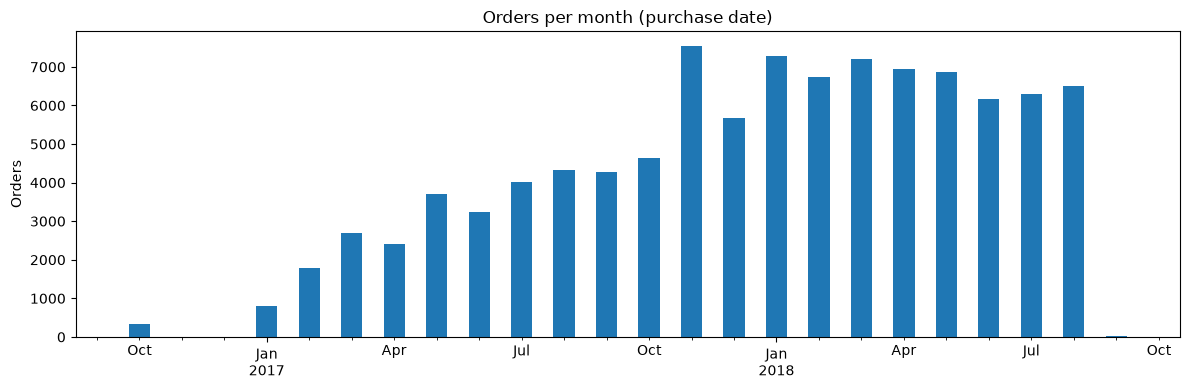

order_purchase_timestamp  order_status
2016-09                   canceled          2
                          delivered         1
                          shipped           1
2016-10                   canceled         24
                          delivered       265
                          invoiced         18
                          processing        2
                          shipped           8
                          unavailable       7
2016-12                   delivered         1
2018-09                   canceled         15
                          shipped           1
2018-10                   canceled          4
dtype: int64

In [10]:
# Reindex so empty months (e.g. Nov 2016) show as 0
month = orders["order_purchase_timestamp"].dt.to_period("M")
monthly = month.value_counts().sort_index()
monthly = monthly.reindex(pd.period_range(monthly.index.min(), monthly.index.max(), freq="M"),
                          fill_value=0)

ax = monthly.plot(kind="bar", figsize=(12, 4))
ax.set_title("Orders per month (purchase date)")
ax.set_xlabel("")
ax.set_ylabel("Orders")
plt.tight_layout()
plt.show()

# What are the edge months made of?
edge = month.astype(str).isin(["2016-09", "2016-10", "2016-12", "2018-09", "2018-10"])
orders[edge].groupby([month[edge], "order_status"]).size()

The first months (Sep–Dec 2016) are tiny, and Nov 2016 has no orders at all. Sep and Oct 2018 are almost all cancellations, so the data effectively ends in Aug 2018. For trends, use **Jan 2017 – Aug 2018**.

### Delivered after the estimated date
The estimate is a date with no time of day, so compare by date.

In [11]:
d = orders[orders["order_delivered_customer_date"].notna()].copy()
d["is_late"] = d["order_delivered_customer_date"].dt.normalize() > d["order_estimated_delivery_date"]
d["days_late"] = (d["order_delivered_customer_date"].dt.normalize()
                  - d["order_estimated_delivery_date"]).dt.days

print(f"Late: {d['is_late'].sum()} of {len(d)} ({d['is_late'].mean():.1%})")
d.loc[d["is_late"], "days_late"].describe()

Late: 6535 of 96476 (6.8%)


count    6535.000000
mean       10.620352
std        14.643844
min         1.000000
25%         3.000000
50%         7.000000
75%        13.000000
max       188.000000
Name: days_late, dtype: float64

## Order items

**Grain:** one row per item (line) in an order. Buying 3 of the same product gives 3 rows.
**Key:** `order_id` + `order_item_id`.
**Links:** `order_id` → orders, `product_id` → products, `seller_id` → sellers.

In [12]:
profile(order_items, "order_items", key=["order_id", "order_item_id"])
order_items.head()

===== order_items =====
Shape (rows, columns): (112650, 7)
Key ['order_id', 'order_item_id'] unique: True
Fully duplicated rows: 0

Data types:
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

Missing values (only columns that have any):
none

Distinct values per column:
order_id               98666
order_item_id             21
product_id             32951
seller_id               3095
shipping_limit_date    93318
price                   5968
freight_value           6999
dtype: int64


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [13]:
order_items["shipping_limit_date"] = pd.to_datetime(order_items["shipping_limit_date"])
order_items[["price", "freight_value"]].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


### Can one order have several items? What's the maximum?

In [14]:
items_per_order = order_items.groupby("order_id").size()

print("Orders with items:", len(items_per_order))
print("Orders with more than one item:", (items_per_order > 1).sum(),
      f"({(items_per_order > 1).mean():.1%})")
print("Maximum items in one order:", items_per_order.max())

# Does order_item_id simply count 1, 2, 3, ... within each order?
max_item_id = order_items.groupby("order_id")["order_item_id"].max()
print("order_item_id max equals item count for every order:", (max_item_id == items_per_order).all())

items_per_order.value_counts().sort_index()

Orders with items: 98666
Orders with more than one item: 9803 (9.9%)
Maximum items in one order: 21
order_item_id max equals item count for every order: True


1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
20        2
21        1
Name: count, dtype: int64

### What's the difference between price and freight_value?
`price` is what the item costs; `freight_value` is the shipping charge for that item. Both are per row (per item), not per order.

In [15]:
print("Zero or negative prices:  ", (order_items["price"] <= 0).sum())
print("Zero freight:              ", (order_items["freight_value"] == 0).sum())
print("Freight higher than price: ", (order_items["freight_value"] > order_items["price"]).sum())

# Is freight repeated per item, or split across items in an order?
multi = order_items[order_items["order_id"].isin(items_per_order[items_per_order > 1].index)]
same_freight = multi.groupby("order_id")["freight_value"].nunique().eq(1).mean()
print(f"Multi-item orders where every item has the same freight: {same_freight:.1%}")

Zero or negative prices:   0
Zero freight:               383
Freight higher than price:  4124
Multi-item orders where every item has the same freight: 79.3%


### Which columns make a row unique?

In [16]:
print("order_id unique on its own:      ", order_items["order_id"].is_unique)
print("order_item_id unique on its own: ", order_items["order_item_id"].is_unique)
print("(order_id, order_item_id) unique:", not order_items.duplicated(subset=["order_id", "order_item_id"]).any())

order_id unique on its own:       False
order_item_id unique on its own:  False
(order_id, order_item_id) unique: True


## Payments

**Grain:** one row per payment of an order.
**Key:** `order_id` + `payment_sequential`.
**Links:** `order_id` → orders.

In [17]:
profile(payments, "payments", key=["order_id", "payment_sequential"])
payments.head()

===== payments =====
Shape (rows, columns): (103886, 5)
Key ['order_id', 'payment_sequential'] unique: True
Fully duplicated rows: 0

Data types:
order_id                    str
payment_sequential        int64
payment_type                str
payment_installments      int64
payment_value           float64
dtype: object

Missing values (only columns that have any):
none

Distinct values per column:
order_id                99440
payment_sequential         29
payment_type                5
payment_installments       24
payment_value           29077
dtype: int64


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [18]:
payments[["payment_sequential", "payment_installments", "payment_value"]].describe()

,payment_sequential,payment_installments,payment_value
count,103886.000000,103886.000000,103886.000000
mean,1.092679,2.853349,154.100380
std,0.706584,2.687051,217.494064
min,1.000000,0.000000,0.000000
25%,1.000000,1.000000,56.790000
50%,1.000000,1.000000,100.000000
75%,1.000000,4.000000,171.837500
max,29.000000,24.000000,13664.080000


### Can one order have several payments? Why?

In [19]:
payments_per_order = payments.groupby("order_id").size()
print("Orders with payments:", len(payments_per_order))
print("Orders with more than one payment:", (payments_per_order > 1).sum())
print("Maximum payments for one order:", payments_per_order.max())

# Which payment types show up in multi-payment orders?
multi_pay = payments[payments["order_id"].isin(payments_per_order[payments_per_order > 1].index)]
has_voucher = multi_pay.groupby("order_id")["payment_type"].apply(lambda s: (s == "voucher").any())
print(f"Multi-payment orders that include a voucher: {has_voucher.mean():.1%}")
multi_pay["payment_type"].value_counts()

Orders with payments: 99440
Orders with more than one payment: 2961
Maximum payments for one order: 29
Multi-payment orders that include a voucher: 90.2%


payment_type
voucher        4581
credit_card    2823
debit_card        3
Name: count, dtype: int64

Several payments mostly means **vouchers**: a customer pays part of an order with one or more vouchers and the rest by card. Installments don't add rows; they are stored in `payment_installments` on a single row.

### Which payment types exist, and how common is each?

In [20]:
type_counts = payments["payment_type"].value_counts()
pd.DataFrame({"payments": type_counts, "pct": (type_counts / len(payments) * 100).round(2)})

,payments,pct
payment_type,,
credit_card,76795,73.92
boleto,19784,19.04
voucher,5775,5.56
debit_card,1529,1.47
not_defined,3,0.00


In [21]:
# Odd values
print("payment_value = 0:", (payments["payment_value"] == 0).sum())
print("payment_installments = 0:", (payments["payment_installments"] == 0).sum())
seq = payments.groupby("order_id")["payment_sequential"].agg(["max", "size"])
print("Orders with gaps in payment_sequential:", (seq["max"] != seq["size"]).sum())
payments[payments["payment_type"] == "not_defined"]

payment_value = 0: 9
payment_installments = 0: 2
Orders with gaps in payment_sequential: 80


,order_id,payment_sequential,payment_type,payment_installments,payment_value
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0


### For a few orders: do payments add up to item prices plus freight?

In [22]:
item_totals = order_items.groupby("order_id")[["price", "freight_value"]].sum()
item_totals["items_total"] = item_totals["price"] + item_totals["freight_value"]
paid = payments.groupby("order_id")["payment_value"].sum().rename("paid")

recon = item_totals.join(paid, how="inner")
recon["diff"] = (recon["paid"] - recon["items_total"]).round(2)

# A few orders, including a multi-item and a multi-payment one
sample_ids = [
    recon.index[0],
    items_per_order[items_per_order > 3].index[0],
    payments_per_order[payments_per_order > 2].index[0],
]
recon.loc[sample_ids]

,price,freight_value,items_total,paid,diff
order_id,,,,,
00010242fe8c5a6d1ba2dd792cb16214,58.90,13.29,72.19,72.19,0.0
00526a9d4ebde463baee25f386963ddc,135.56,33.60,169.16,169.16,0.0
009ac365164f8e06f59d18a08045f6c4,16.90,15.10,32.00,32.00,0.0


In [23]:
# And for all orders
print("Orders compared:", len(recon))
print(f"Match within 1 cent: {(recon['diff'].abs() <= 0.01).mean():.1%}")
print("Paid more than items + freight:", (recon["diff"] > 0.01).sum())
print("Paid less than items + freight:", (recon["diff"] < -0.01).sum())
recon.loc[recon["diff"].abs() > 0.01, "diff"].describe()

Orders compared: 98665
Match within 1 cent: 99.7%
Paid more than items + freight: 264
Paid less than items + freight: 39


count    303.000000
mean       9.475446
std       18.077227
min      -51.620000
25%        1.355000
50%        5.410000
75%       11.830000
max      182.810000
Name: diff, dtype: float64

## Reviews

**Grain:** one row per review of an order (in theory).
**Key:** `review_id` alone is **not** unique. Use `review_id` + `order_id`.
**Links:** `order_id` → orders.

In [24]:
profile(reviews, "reviews", key=["review_id", "order_id"])
reviews.head()

===== reviews =====
Shape (rows, columns): (99224, 7)
Key ['review_id', 'order_id'] unique: True
Fully duplicated rows: 0

Data types:
review_id                    str
order_id                     str
review_score               int64
review_comment_title         str
review_comment_message       str
review_creation_date         str
review_answer_timestamp      str
dtype: object

Missing values (only columns that have any):
review_comment_title      87656
review_comment_message    58247
dtype: int64

Distinct values per column:
review_id                  98410
order_id                   98673
review_score                   5
review_comment_title        4527
review_comment_message     36159
review_creation_date         636
review_answer_timestamp    98248
dtype: int64


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [25]:
reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"])
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])

# Missing titles and messages: the score is mandatory, the text is optional
print(f"No title:   {reviews['review_comment_title'].isna().mean():.1%}")
print(f"No message: {reviews['review_comment_message'].isna().mean():.1%}")

No title:   88.3%
No message: 58.7%


### Is there exactly one review per order? Find exceptions.

In [26]:
reviews_per_order = reviews.groupby("order_id").size()
print("Orders with more than one review:", (reviews_per_order > 1).sum(),
      "| max:", reviews_per_order.max())
print("Orders with no review:", (~orders["order_id"].isin(reviews["order_id"])).sum())

orders_per_review = reviews.groupby("review_id")["order_id"].nunique()
print("review_ids used for more than one order:", (orders_per_review > 1).sum())

# Example: one order with several reviews
example_order = reviews_per_order[reviews_per_order > 1].index[0]
reviews[reviews["order_id"] == example_order]

Orders with more than one review: 547 | max: 3
Orders with no review: 768
review_ids used for more than one order: 789


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
22423,2a74b0559eb58fc1ff842ecc999594cb,0035246a40f520710769010f752e7507,5,NaN,Estou acostumada a comprar produtos pelo barat...,2017-08-25,2017-08-29 21:45:57
25612,89a02c45c340aeeb1354a24e7d4b2c1e,0035246a40f520710769010f752e7507,5,NaN,NaN,2017-08-29,2017-08-30 01:59:12


In [27]:
# Example: one review_id attached to several orders
example_review = orders_per_review[orders_per_review > 1].index[0]
reviews[reviews["review_id"] == example_review]

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07,2018-03-20 18:08:23


### Distribution of review scores (1–5)

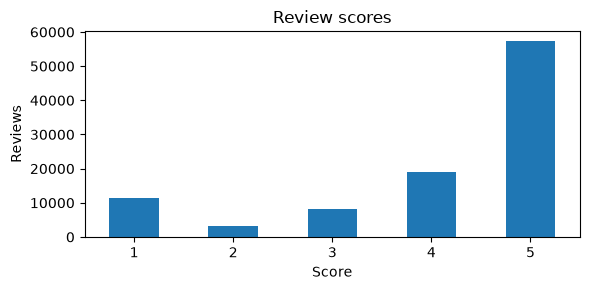

review_score
1    11.5
2     3.2
3     8.2
4    19.3
5    57.8
Name: count, dtype: float64

In [28]:
scores = reviews["review_score"].value_counts().sort_index()
ax = scores.plot(kind="bar", figsize=(6, 3), rot=0)
ax.set_title("Review scores")
ax.set_xlabel("Score")
ax.set_ylabel("Reviews")
plt.tight_layout()
plt.show()
(scores / scores.sum() * 100).round(1)

## Customers

**Grain:** one row per `customer_id`, which is created **per order**, not per person.
**Key:** `customer_id`.
**Links:** `customer_id` → orders. `customer_zip_code_prefix` → geolocation (many-to-many, see below).

In [29]:
profile(customers, "customers", key="customer_id")
customers.head()

===== customers =====
Shape (rows, columns): (99441, 5)
Key ['customer_id'] unique: True
Fully duplicated rows: 0

Data types:
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

Missing values (only columns that have any):
none

Distinct values per column:
customer_id                 99441
customer_unique_id          96096
customer_zip_code_prefix    14994
customer_city                4119
customer_state                 27
dtype: int64


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


### How many unique customer_id vs customer_unique_id?

In [30]:
print("customer_id:       ", customers["customer_id"].nunique())
print("customer_unique_id:", customers["customer_unique_id"].nunique())
print("orders:            ", len(orders))
print("Every order has its own customer_id:", orders["customer_id"].is_unique)

customer_id:        99441
customer_unique_id: 96096
orders:             99441
Every order has its own customer_id: True


### Which one represents a real person?
`customer_unique_id`. Every order gets a fresh `customer_id` (99,441 orders → 99,441 customer_ids), so `customer_id` is really an "order's customer" key. `customer_unique_id` stays the same across a person's orders.

### How many people placed more than one order?

In [31]:
orders_per_person = (orders.merge(customers, on="customer_id")
                           .groupby("customer_unique_id")["order_id"].nunique())
print("People:", len(orders_per_person))
print("People with more than one order:", (orders_per_person > 1).sum(),
      f"({(orders_per_person > 1).mean():.1%})")
print("Most orders by one person:", orders_per_person.max())
orders_per_person.value_counts().sort_index()

People: 96096
People with more than one order: 2997 (3.1%)
Most orders by one person: 17


order_id
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

In [32]:
customers["customer_state"].value_counts().head(10)

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: count, dtype: int64

## Products

**Grain:** one row per product. **Key:** `product_id`.
**Links:** `product_id` → order_items. `product_category_name` → category_translation.

In [33]:
profile(products, "products", key="product_id")
products.head()

===== products =====
Shape (rows, columns): (32951, 9)
Key ['product_id'] unique: True
Fully duplicated rows: 0

Data types:
product_id                        str
product_category_name             str
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object

Missing values (only columns that have any):
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Distinct values per column:
product_id                    32951
product_category_name            73
product_name_lenght              66
product_description_lenght     2960
product_photos_

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [34]:
products.describe().T

,count,mean,std,min,25%,50%,75%,max
product_name_lenght,32341.0,48.476949,10.245741,5.0,42.0,51.0,57.0,76.0
product_description_lenght,32341.0,771.495285,635.115225,4.0,339.0,595.0,972.0,3992.0
product_photos_qty,32341.0,2.188986,1.736766,1.0,1.0,1.0,3.0,20.0
product_weight_g,32949.0,2276.472488,4282.038731,0.0,300.0,700.0,1900.0,40425.0
product_length_cm,32949.0,30.815078,16.914458,7.0,18.0,25.0,38.0,105.0
product_height_cm,32949.0,16.937661,13.637554,2.0,8.0,13.0,21.0,105.0
product_width_cm,32949.0,23.196728,12.079047,6.0,15.0,20.0,30.0,118.0


Note the misspelled column names in the source: `product_name_lenght` and `product_description_lenght`.

### How many products have no category?

In [35]:
no_cat = products["product_category_name"].isna()
print("Products with no category:", no_cat.sum())

# The same 610 rows are also missing name length, description length and photos
print(products.loc[no_cat, ["product_name_lenght", "product_description_lenght", "product_photos_qty"]].isna().all())

print("\nZero weight:", (products["product_weight_g"] == 0).sum())
products[products["product_weight_g"].isna()]

Products with no category: 610
product_name_lenght           True
product_description_lenght    True
product_photos_qty            True
dtype: bool

Zero weight: 4


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### How do you get English category names?

In [36]:
profile(category_translation, "category_translation", key="product_category_name")
category_translation.head()

===== category_translation =====
Shape (rows, columns): (71, 2)
Key ['product_category_name'] unique: True
Fully duplicated rows: 0

Data types:
product_category_name            str
product_category_name_english    str
dtype: object

Missing values (only columns that have any):
none

Distinct values per column:
product_category_name            71
product_category_name_english    71
dtype: int64


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [37]:
products_en = products.merge(category_translation, on="product_category_name", how="left")
print("Rows before / after merge:", len(products), len(products_en))

# Categories that exist in products but have no translation
missing = set(products["product_category_name"].dropna()) - set(category_translation["product_category_name"])
print("Categories with no English name:", missing)

products_en["product_category_name_english"].value_counts().head(10)

Rows before / after merge: 32951 32951
Categories with no English name: {'pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos'}


product_category_name_english
bed_bath_table           3029
sports_leisure           2867
furniture_decor          2657
health_beauty            2444
housewares               2335
auto                     1900
computers_accessories    1639
toys                     1411
watches_gifts            1329
telephony                1134
Name: count, dtype: int64

## Sellers

**Grain:** one row per seller. **Key:** `seller_id`.
**Links:** `seller_id` → order_items. `seller_zip_code_prefix` → geolocation.

In [38]:
profile(sellers, "sellers", key="seller_id")
sellers.head()

===== sellers =====
Shape (rows, columns): (3095, 4)
Key ['seller_id'] unique: True
Fully duplicated rows: 0

Data types:
seller_id                   str
seller_zip_code_prefix    int64
seller_city                 str
seller_state                str
dtype: object

Missing values (only columns that have any):
none

Distinct values per column:
seller_id                 3095
seller_zip_code_prefix    2246
seller_city                611
seller_state                23
dtype: int64


,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


### Which states have the most sellers?

In [39]:
seller_states = sellers["seller_state"].value_counts()
print("States with sellers:", len(seller_states), "of 27")
seller_states.head(10)

States with sellers: 23 of 27


seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
Name: count, dtype: int64

## Geolocation

**Grain:** one row per (zip code prefix, lat/lng point). There are many points per prefix.
**Key:** none. There is no unique column, and a quarter of the rows are exact duplicates.
**Links:** `geolocation_zip_code_prefix` ↔ customers and sellers zip prefixes.

In [40]:
profile(geolocation, "geolocation")
geolocation.head()

===== geolocation =====
Shape (rows, columns): (1000163, 5)
Fully duplicated rows: 261831

Data types:
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str
dtype: object

Missing values (only columns that have any):
none

Distinct values per column:
geolocation_zip_code_prefix     19015
geolocation_lat                717372
geolocation_lng                717615
geolocation_city                 8011
geolocation_state                  27
dtype: int64


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


### Is the zip code prefix in geolocation unique? If not, why?

In [41]:
rows_per_zip = geolocation.groupby("geolocation_zip_code_prefix").size()
print("zip prefix unique:", geolocation["geolocation_zip_code_prefix"].is_unique)
print("Distinct prefixes:", len(rows_per_zip), "| max rows for one prefix:", rows_per_zip.max())
print("Prefixes with more than one city spelling:",
      (geolocation.groupby("geolocation_zip_code_prefix")["geolocation_city"].nunique() > 1).sum())

# Example: one prefix has many lat/lng points
geolocation[geolocation["geolocation_zip_code_prefix"] == rows_per_zip.idxmax()].head()

zip prefix unique: False
Distinct prefixes: 19015 | max rows for one prefix: 1146
Prefixes with more than one city spelling: 8556


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
470805,24220,-22.905817,-43.106989,niteroi,RJ
470811,24220,-22.902306,-43.112545,niteroi,RJ
470812,24220,-22.904567,-43.110491,niteroi,RJ
470820,24220,-22.902575,-43.109192,niteroi,RJ
470821,24220,-22.907500,-43.106170,niteroi,RJ


The prefix is only the **first 5 digits** of a Brazilian zip code (CEP), so it covers an area with many addresses. Each row is a different point in that area. The same city is also spelled several ways (accents, case). To join, collapse to one row per prefix first (e.g. mean lat/lng).

In [42]:
# Points outside Brazil's rough bounding box
outside = (~geolocation["geolocation_lat"].between(-34, 5.5)
           | ~geolocation["geolocation_lng"].between(-74, -34))
print("Points outside Brazil:", outside.sum())

print("Customer zips not in geolocation:",
      (~customers["customer_zip_code_prefix"].isin(geolocation["geolocation_zip_code_prefix"])).sum())
print("Seller zips not in geolocation:",
      (~sellers["seller_zip_code_prefix"].isin(geolocation["geolocation_zip_code_prefix"])).sum())

Points outside Brazil: 42
Customer zips not in geolocation: 278
Seller zips not in geolocation: 7


## Connecting the tables

```mermaid
erDiagram
    CUSTOMERS ||--|| ORDERS : "customer_id (1 per order)"
    ORDERS ||--o{ ORDER_ITEMS : order_id
    ORDERS ||--o{ PAYMENTS : order_id
    ORDERS ||--o{ REVIEWS : order_id
    PRODUCTS ||--o{ ORDER_ITEMS : product_id
    SELLERS ||--o{ ORDER_ITEMS : seller_id
    CATEGORY_TRANSLATION ||--o{ PRODUCTS : product_category_name
    GEOLOCATION }o--o{ CUSTOMERS : zip_code_prefix
    GEOLOCATION }o--o{ SELLERS : zip_code_prefix
```

- customers → orders is **one-to-one** on `customer_id` (one-to-many on `customer_unique_id`).
- orders → order_items / payments / reviews are **one-to-many**.
- products / sellers → order_items are **one-to-many**.
- geolocation ↔ customers / sellers is **many-to-many** on zip prefix, until geolocation is reduced to one row per prefix.

### Do all the links resolve? (orphan keys)

In [43]:
def orphans(child, child_col, parent, parent_col):
    return (~child[child_col].isin(parent[parent_col])).sum()

pd.Series({
    "orders.customer_id not in customers":     orphans(orders, "customer_id", customers, "customer_id"),
    "customers with no order":                 orphans(customers, "customer_id", orders, "customer_id"),
    "order_items.order_id not in orders":      orphans(order_items, "order_id", orders, "order_id"),
    "order_items.product_id not in products":  orphans(order_items, "product_id", products, "product_id"),
    "order_items.seller_id not in sellers":    orphans(order_items, "seller_id", sellers, "seller_id"),
    "payments.order_id not in orders":         orphans(payments, "order_id", orders, "order_id"),
    "reviews.order_id not in orders":          orphans(reviews, "order_id", orders, "order_id"),
    "orders with no items":                    orphans(orders, "order_id", order_items, "order_id"),
    "orders with no payment":                  orphans(orders, "order_id", payments, "order_id"),
    "orders with no review":                   orphans(orders, "order_id", reviews, "order_id"),
})

orders.customer_id not in customers         0
customers with no order                     0
order_items.order_id not in orders          0
order_items.product_id not in products      0
order_items.seller_id not in sellers        0
payments.order_id not in orders             0
reviews.order_id not in orders              0
orders with no items                      775
orders with no payment                      1
orders with no review                     768
dtype: int64

### Join orders with order items: does the row count change as you expected?

In [44]:
inner = orders.merge(order_items, on="order_id", how="inner")
left = orders.merge(order_items, on="order_id", how="left")

print("orders:              ", len(orders))
print("order_items:         ", len(order_items))
print("inner join:          ", len(inner), "(= order_items, every item has an order)")
print("left join:           ", len(left), "(= items + orders without items)")
print("orders without items:", len(left) - len(inner))

# Which orders have no items?
left[left["order_item_id"].isna()]["order_status"].value_counts()

orders:               99441
order_items:          112650
inner join:           112650 (= order_items, every item has an order)
left join:            113425 (= items + orders without items)
orders without items: 775


order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64

Joining one-to-many multiplies rows: 99,441 orders become 112,650 rows, one per item. Summing an order-level column (like payment totals) after this join would double-count. The left join adds 775 orders with no items, which are mostly `unavailable` and `canceled`.

## Summary

The write-up per table (grain, key, links, missing values, surprises) and the **Questions for the pipeline** list are in [`docs/data_sources.md`](../docs/data_sources.md).